# Projected time evolution (ptVMC)

This notebook shows how to simulate unitary dynamics, $|\psi(t)\rangle = e^{-iHt}|\psi(0)\rangle$, with projected time-dependent VMC (ptVMC). The TDVP example integrates an equation of motion for the network parameters. ptVMC instead turns every time step into an optimisation: given the state $|\psi_{\theta_n}\rangle$ at time $t_n$, the state at $t_{n+1} = t_n + \tau$ is the one closest to the propagated state,

$$
\theta_{n+1} = \operatorname*{arg\,min}_\theta \; \mathcal I\big(\psi_\theta,\; \hat U(\tau)\,\psi_{\theta_n}\big),
\qquad
\mathcal I(\psi, \hat O\chi) = 1 - \frac{|\langle\psi|\hat O|\chi\rangle|^2}{\langle\psi|\psi\rangle\,\langle\chi|\hat O^\dagger\hat O|\chi\rangle},
$$

where $\hat U(\tau)\approx e^{-iH\tau}$. Each minimisation is an infidelity optimisation, as in the infidelity optimisation example, with `jVMC_exp.objective_function.Infidelity`. Its reference state $|\chi\rangle$ is the variational state at the previous time, and its operator is (a factor of) the short-time propagator. The infidelity left after each fit measures the error of that step, and this local error control is the main appeal of ptVMC. The cost is an optimisation at every step, instead of a single linear solve. We follow the scheme of L. Gravina, V. Savona and F. Vicentini, *Neural projected quantum dynamics: a systematic study*, Quantum **9**, 1803 (2025).

The library runs this loop with `jVMC_exp.util.PTVMC`, which takes the optimizer of the fits, and a propagator such as `jVMC_exp.util.ProductExpansion`.

We use the same system as the TDVP example: an Ising chain in a transverse and a longitudinal field, with periodic boundary conditions,

$$
H = -\sum_{l} \sigma^z_l \sigma^z_{l+1} + g \sum_{l} \sigma^x_l + h \sum_{l} \sigma^z_l ,
$$

with the same network and initial state, so the two methods can be compared directly.

The example is structured as follows:

1. Set up the Hamiltonian, the variational state and its sampler.
2. Build the short-time propagator as a product of operators that are linear in $H$.
3. Set up the optimizer of the fits and the ptVMC driver.
4. Run the time evolution.
5. Compare with the exact evolution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import jVMC_exp
import jVMC_exp.operator.discrete as op

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Running in single-node mode (JVMC_USE_DISTRIBUTED not set)


## 1. Hamiltonian, state and sampler

Only the variational state $|\psi_\theta\rangle$ has to be set up. The driver keeps a copy of it as the reference state $|\chi\rangle$, which holds the parameters of `psi` from the beginning of the current fit and stays fixed during it. Since $\chi = \psi_\theta$ at the beginning of every fit, the samples of $|\chi\rangle$ are the samples of `psi` drawn at that moment, so no second sampler is needed.

As in the TDVP example, the initial state is the network at its random initialisation, with the same seed. The system is small ($2^6 = 64$ configurations), so we use an `ExactSampler`. This isolates the errors of ptVMC from the sampling noise; see the end of the notebook for Monte Carlo sampling.

In [2]:
L = 6
g = -0.7
h = 0.1

tau = 0.05  # time step
t_max = 2.0

# Hamiltonian and transverse magnetization
hamiltonian = 0
M_x = 0
for l in range(L):
    hamiltonian += -1 * op.SigmaZ(l) * op.SigmaZ((l + 1) % L) + g * op.SigmaX(l) + h * op.SigmaZ(l)
    M_x += op.SigmaX(l)
M_x /= L

net = jVMC_exp.nets.CpxRBM(num_hidden=10, bias=True)
psi = jVMC_exp.vqs.NQS(net, sample_shape=L, batch_size=2**L, seed=123)
sampler = jVMC_exp.sampler.ExactSampler(psi)

print("Number of parameters: ", psi.num_parameters)

Number of parameters:  70


## 2. The short-time propagator

`Infidelity` applies an operator $\hat O$ to the reference state, and its cost grows with the number of configurations that $\hat O$ connects. The exact propagator $e^{-iH\tau}$ connects all of them, so we approximate it by its Taylor expansion of order $o$ and write that as a product of $o$ factors linear in $H$:

$$
e^{-iH\tau} = \sum_{k=0}^{o}\frac{(-iH\tau)^k}{k!} + \mathcal O(\tau^{o+1})
= \prod_{k=1}^{o}\big(1 - i a_k \tau H\big) + \mathcal O(\tau^{o+1}),
\qquad a_k = -\frac{1}{z_k},
$$

where $z_k$ are the (complex) roots of the polynomial $\sum_{k=0}^{o} z^k/k!$. Gravina et al. call this a product expansion. Each factor $\hat O_k = 1 - i a_k\tau H$ connects only as many configurations as $H$ itself. The factors are applied one after the other, so a time step consists of $o$ fits, each targeting $\hat O_k|\psi_{\theta}\rangle$ for the current $\theta$. We use $o = 4$, which has the same order as the RK4 integrator.

`jVMC_exp.util.ProductExpansion(tau, order)` computes the coefficients $a_k$, and its method `stages(hamiltonian)` returns the factors as a list of `Stage`s, each with $\hat O_k$, its adjoint $\hat O_k^\dagger = 1 + i a_k^* \tau H$, which `Infidelity` needs as well, and the flag `unitary=False`. With this flag, `Infidelity` normalises the infidelity by $\langle\chi|\hat O_k^\dagger\hat O_k|\chi\rangle$, as in the formula above.

The cell below checks the expansion against the exact propagator, using dense matrices that `to_dense()` builds on the basis of the `ExactSampler`.

In [3]:
order = 4
propagator = jVMC_exp.util.ProductExpansion(tau, order)
print("a_k =", np.round(propagator.coefficients, 4))

# Check with dense matrices that the product of the stages approximates exp(-iH tau)
basis = sampler.basis
H_dense = np.asarray(hamiltonian.to_dense(basis))
M_x_dense = np.asarray(M_x.to_dense(basis))
eigenvalues, eigenvectors = np.linalg.eigh(H_dense)


def exact_propagator(t):
    return eigenvectors @ np.diag(np.exp(-1j * eigenvalues * t)) @ eigenvectors.conj().T


product = np.eye(2**L, dtype=complex)
for stage in propagator.stages(hamiltonian):
    product = np.asarray(stage.operator.to_dense(basis)) @ product

print(f"||prod_k O_k - exp(-iH tau)||  = {np.linalg.norm(product - exact_propagator(tau), 2):.2e}")
print(f"(||H|| tau)^(o+1) / (o+1)!     = {(np.abs(eigenvalues).max() * tau) ** (order + 1) / np.prod(np.arange(1, order + 2)):.2e}")

a_k = [0.0426+0.3946j 0.0426-0.3946j 0.4574+0.2351j 0.4574-0.2351j]
||prod_k O_k - exp(-iH tau)||  = 5.46e-05
(||H|| tau)^(o+1) / (o+1)!     = 5.46e-05


## 3. The optimizer of the fits and the driver

Each fit is a short minimisation with stochastic reconfiguration, as in the infidelity optimisation example. It starts from the current state, which is already close to its target since $\hat O_k = 1 + \mathcal O(\tau)$, so a few steps are enough. A learning rate of $0.5$ converges reliably here; larger rates can overshoot and lose the state.

`PTVMC(optimizer, fit_stepper, fit_steps)` takes the optimizer, the stepper whose time step is the learning rate of the fits, and the number of steps of every fit. The schedule of the stepper, if it has one, restarts at every fit. The driver evolves the state and uses the sampler of the optimizer, and records the data in its `output_manager`.

In [4]:
num_fit_steps = 20
learning_rate = 0.5

opt = jVMC_exp.optimizer.SR(sampler, psi, diagonal_shift=1e-4)
ptvmc = jVMC_exp.util.PTVMC(opt, jVMC_exp.stepper.Euler(learning_rate), num_fit_steps)

## 4. Run the time evolution

`time_evolution(t_max, objective_function, propagator, ...)` mirrors `TDVP.time_evolution()`: the objective function is the `Observable` of the Hamiltonian, and the propagator takes the place of the stepper. Every time step applies the $o$ factors one after the other, each with one fit. At the beginning of every step, and at the final time, the driver measures the energy, recorded as `"energy"`, and the observables passed in `observables`, here the transverse magnetization $M_x = \frac{1}{L}\sum_l\sigma^x_l$. With `save_meta_data=True` it also records the infidelity of every fit, at the end of the fit: `metadata["infidelity"]` has one entry per fit, and `metadata["total_infidelity"]` their sum $\sum_k \mathcal I_k$, the infidelity added by the step.

The callback runs after every measurement. Here it stores the full state vector with `psi.to_array(basis)`, which is only possible for small systems, to compare with the exact evolution below.

In [5]:
states = []
observables, metadata = ptvmc.time_evolution(
    t_max,
    jVMC_exp.objective_function.Observable(hamiltonian),
    propagator,
    observables={"magnetization": M_x},
    callback=lambda: states.append(np.asarray(psi.to_array(basis))),
    save_meta_data=True,
)

times = np.array(observables["times"])
energy = np.array(observables["energy"]["mean"])
magnetization = np.array(observables["magnetization"]["mean"])
# One entry per step, the sum of the infidelities of its fits
fit_infidelity = np.array(metadata["total_infidelity"]["mean"])

100%|██████████| 40/40 [02:16<00:00,  3.42s/it, t=2.0000/2.0, E=-4.198681, I=4.61e-14]

Recorded timings:
    - sampling: 2.559425s (2.4%)
    - compute objective function and gradient: 62.853819s (57.9%)


    - solve: 43.160642s (39.8%)
    Total: 108.573886s


## 5. Comparison with the exact evolution

The exact state $e^{-iHt}|\psi(0)\rangle$ follows from the dense Hamiltonian. We compare:

- the **energy**, which unitary evolution conserves, so any drift is an error of the simulation;
- the **transverse magnetization**, with its exact value;
- the **infidelity with the exact state**, $1 - |\langle\psi_{\rm exact}(t)|\psi_\theta(t)\rangle|^2$ for normalised states, which collects all errors up to time $t$;
- the **infidelity of the fits**, summed over the $o$ fits of each step and plotted at the end of the step, i.e. the error added by the optimisation at every step.

The infidelity with the exact state collects two errors: the residual infidelity of the fits, and the truncation of the propagator at order $o$. Here the truncation error is negligible. The infidelity with the exact state grows while the fits leave a residual of about $10^{-7}$, and stays flat once the fits become essentially exact, after $t\approx 1$. The truncation error matters for a lower order or a larger time step: with $o = 2$ and the same $\tau$, the infidelity with the exact state already reaches about $7\times10^{-4}$ at $t = 0.5$.

Largest deviation of the energy:         4.57e-04
Largest deviation of the magnetization:  2.53e-04
Infidelity with the exact state at t_max: 1.21e-05


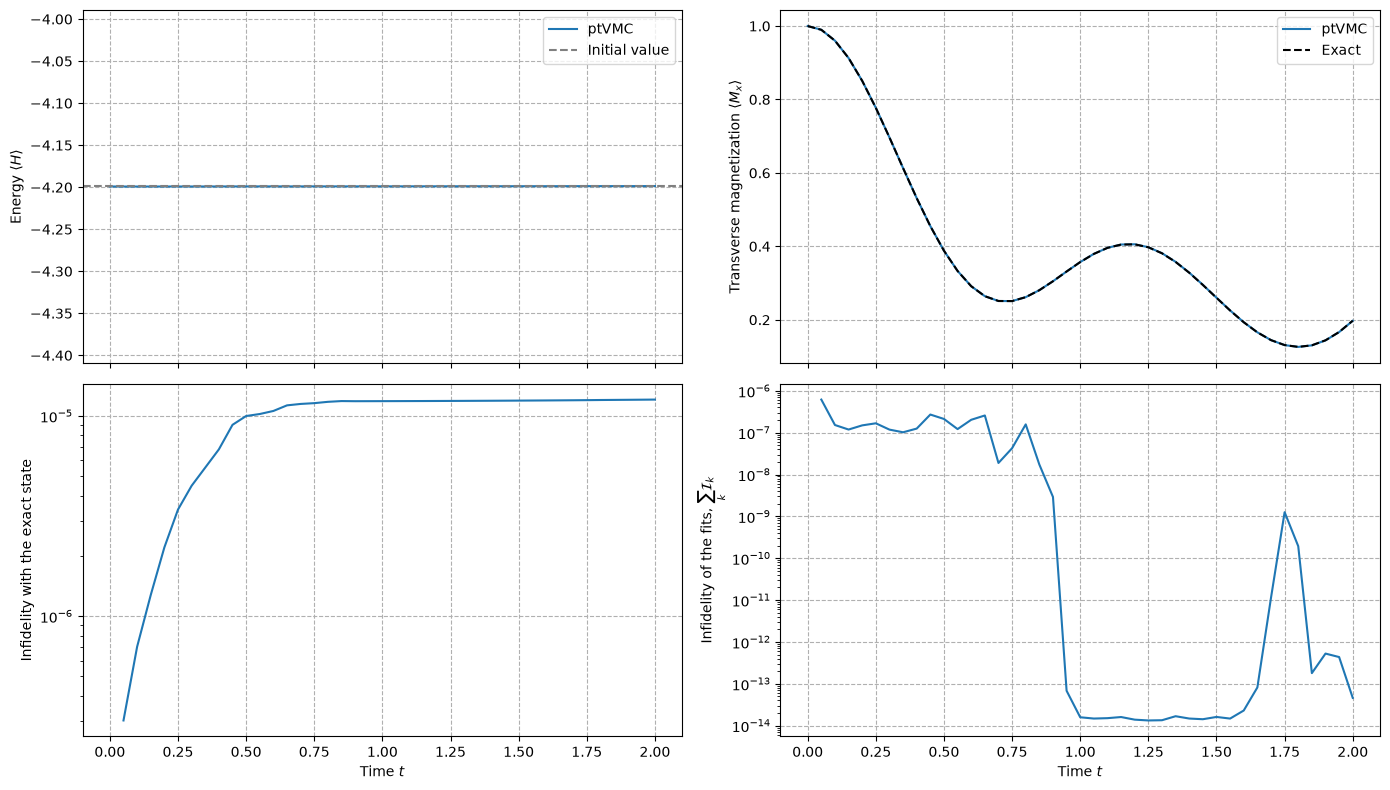

In [6]:
exact_states = [exact_propagator(t) @ states[0] for t in times]
exact_magnetization = np.array([np.real(np.vdot(v, M_x_dense @ v)) for v in exact_states])
exact_infidelity = np.array([1 - np.abs(np.vdot(v, s)) ** 2 for v, s in zip(exact_states, states)])

fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

ax = axs[0, 0]
ax.plot(times, energy, label="ptVMC")
ax.axhline(energy[0], ls="--", color="gray", label="Initial value")
ax.set_ylim(energy[0] - 0.05 * abs(energy[0]), energy[0] + 0.05 * abs(energy[0]))
ax.set_ylabel(r"Energy $\langle H\rangle$")
ax.legend()

ax = axs[0, 1]
ax.plot(times, magnetization, label="ptVMC")
ax.plot(times, exact_magnetization, "--", color="black", label="Exact")
ax.set_ylabel(r"Transverse magnetization $\langle M_x\rangle$")
ax.legend()

ax = axs[1, 0]
ax.plot(times[1:], exact_infidelity[1:])
ax.set_yscale("log")
ax.set_ylabel(r"Infidelity with the exact state")

ax = axs[1, 1]
ax.plot(times[1:], fit_infidelity)
ax.set_yscale("log")
ax.set_ylabel(r"Infidelity of the fits, $\sum_k \mathcal{I}_k$")

for ax in axs.flat:
    ax.grid(ls="--")
for ax in axs[1]:
    ax.set_xlabel(r"Time $t$")

plt.tight_layout()

print(f"Largest deviation of the energy:         {np.abs(energy - energy[0]).max():.2e}")
print(f"Largest deviation of the magnetization:  {np.abs(magnetization - exact_magnetization).max():.2e}")
print(f"Infidelity with the exact state at t_max: {exact_infidelity[-1]:.2e}")

## Going further

- **Monte Carlo sampling.** For larger systems, replace the `ExactSampler` with an `MCSampler`, as in the infidelity optimisation example; the reference state still reuses the samples of `psi`. The estimate of the infidelity then fluctuates, and its variance can be reduced with `control_variate="adaptive"` in `PTVMC`, which passes it to every `Infidelity`. The control variate leaves the gradient unchanged, and for the non-unitary factors used here `Infidelity` estimates the value from the reference samples reweighted by $|\hat O_k\chi|^2$, so the value stays unbiased. More fit steps are usually needed as well.
- **Other propagators.** A propagator is a subclass of `jVMC_exp.util.AbstractPropagator` whose method `stages(hamiltonian)` returns a list of `jVMC_exp.util.Stage(operator, conjugated_operator, unitary)`. For example, a Trotter product of two-site gates $e^{-ih_{l,l+1}\tau}$ has one unitary stage per gate, each built from its dense $4\times4$ matrix with `jVMC_exp.util.util.matrix_to_jvmc_operator(matrix, sites, return_conjugate=True)`.